In [1]:
import os
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Configurações visuais do Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

# Define diretório local de dados
DATA_DIR = os.path.abspath("../data")
print(f"Diretório de dados: {DATA_DIR}")

Diretório de dados: /home/giovanna/Documents/projeto_aprend_prof/small-data-vit-skin-lesions/data


Carregamento do CIFAR-100

In [3]:
# Carrega sem transformações complexas para analisar os pixels originais (0 a 255)
raw_transform = transforms.Compose([
    transforms.ToTensor()
])

# Com download=False, o PyTorch carrega instantaneamente os ficheiros já extraídos
train_dataset = torchvision.datasets.CIFAR100(root=DATA_DIR, train=True, download=False, transform=raw_transform)
test_dataset = torchvision.datasets.CIFAR100(root=DATA_DIR, train=False, download=False, transform=raw_transform)

print(f"--- Resumo do CIFAR-100 ---")
print(f"Amostras de Treino: {len(train_dataset)}")
print(f"Amostras de Teste:  {len(test_dataset)}")
print(f"Dimensão da Imagem: {train_dataset[0][0].shape}")

--- Resumo do CIFAR-100 ---
Amostras de Treino: 50000
Amostras de Teste:  10000
Dimensão da Imagem: torch.Size([3, 32, 32])


Verificação do Balanceamento de Classes

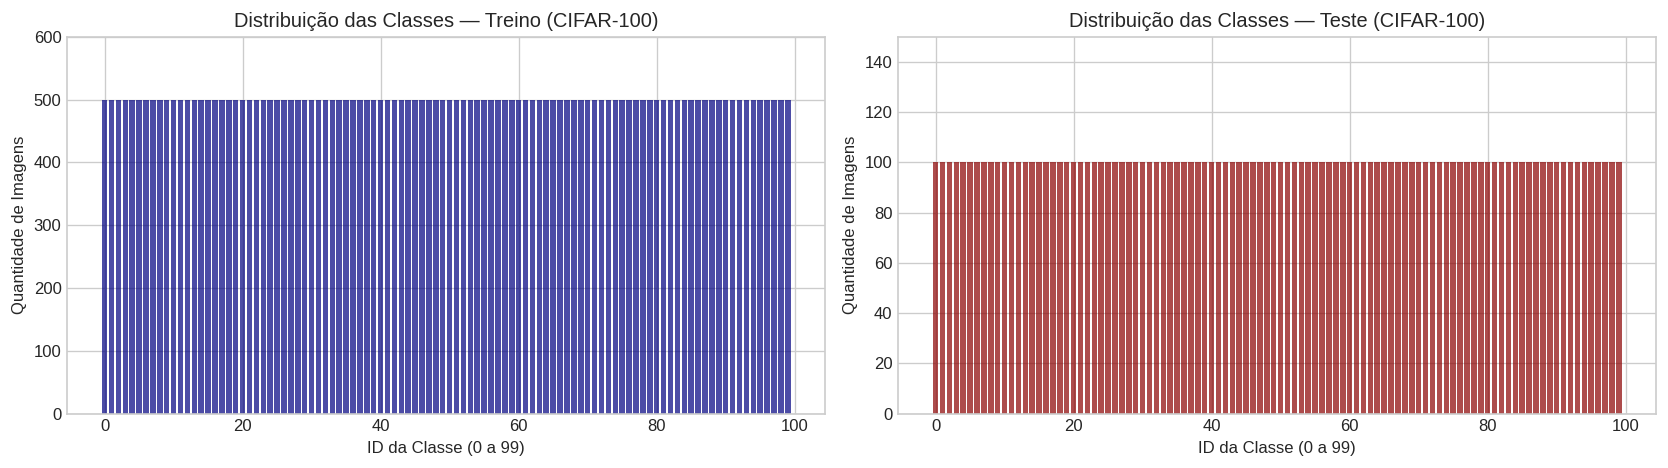

Cada classe possui exatamente 500 imagens no treino e 100 no teste. A base é 100% balanceada!


In [4]:
train_targets = train_dataset.targets
test_targets = test_dataset.targets

train_counts = Counter(train_targets)
test_counts = Counter(test_targets)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(list(train_counts.keys()), list(train_counts.values()), color='navy', alpha=0.7)
axes[0].set_title("Distribuição das Classes — Treino (CIFAR-100)")
axes[0].set_xlabel("ID da Classe (0 a 99)")
axes[0].set_ylabel("Quantidade de Imagens")
axes[0].set_ylim(0, 600)

axes[1].bar(list(test_counts.keys()), list(test_counts.values()), color='darkred', alpha=0.7)
axes[1].set_title("Distribuição das Classes — Teste (CIFAR-100)")
axes[1].set_xlabel("ID da Classe (0 a 99)")
axes[1].set_ylabel("Quantidade de Imagens")
axes[1].set_ylim(0, 150)

plt.tight_layout()
plt.show()

print(f"Cada classe possui exatamente {train_counts[0]} imagens no treino e {test_counts[0]} no teste. A base é 100% balanceada!")

Visualização de uma Grade de Exemplo

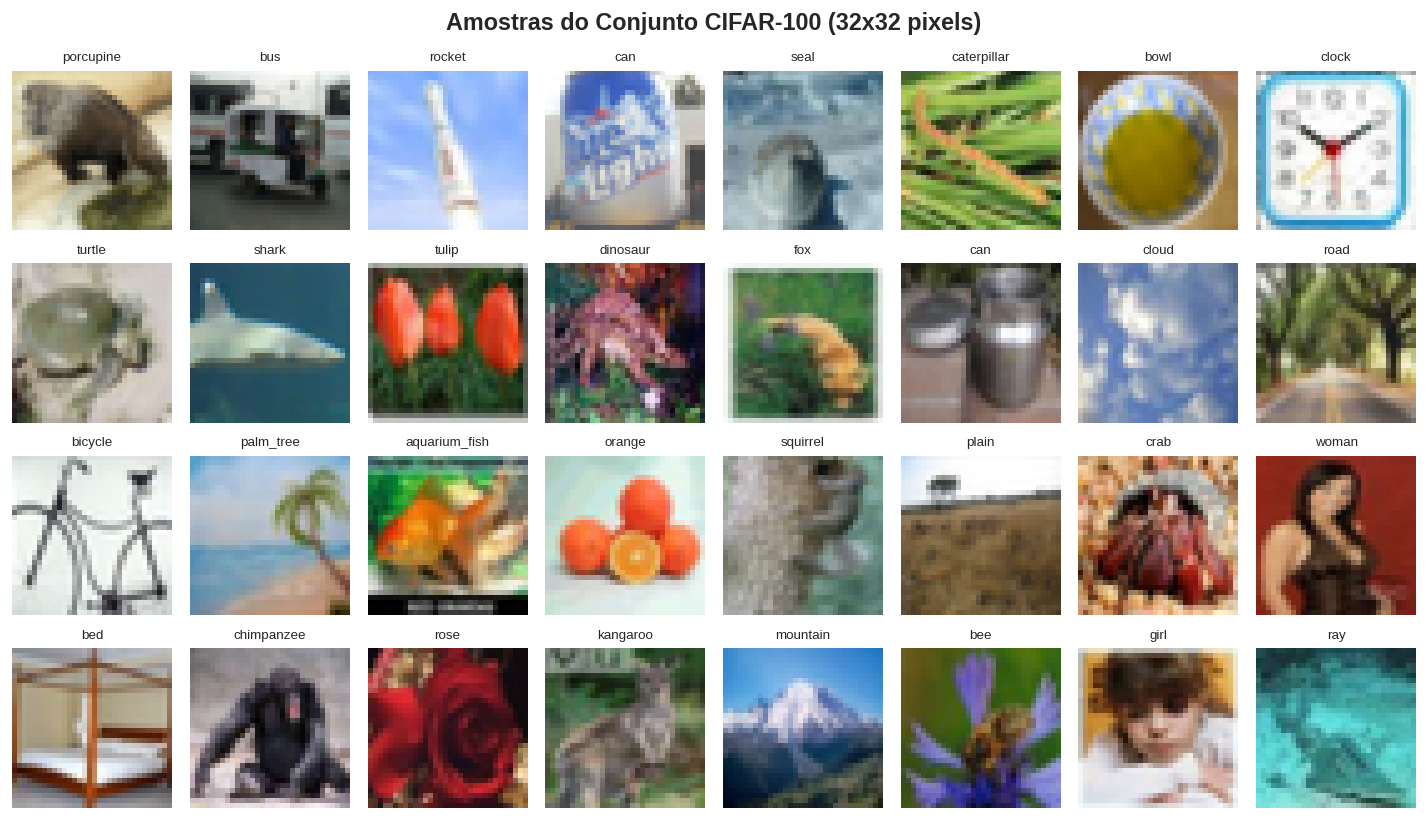

In [5]:
fig, axes = plt.subplots(4, 8, figsize=(12, 7))
fig.suptitle("Amostras do Conjunto CIFAR-100 (32x32 pixels)", fontsize=14, fontweight='bold')

np.random.seed(42)
indices = np.random.choice(len(train_dataset), 32, replace=False)

for i, idx in enumerate(indices):
    ax = axes[i // 8, i % 8]
    img, label = train_dataset[idx]
    # Permuta dimensão PyTorch (C, H, W) -> Matplotlib (H, W, C)
    img_np = img.permute(1, 2, 0).numpy()
    
    ax.imshow(img_np)
    ax.set_title(train_dataset.classes[label], fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()

Cálculo das Estatísticas de Canais RGB (Média e Desvio Padrão)

In [6]:
loader = torch.utils.data.DataLoader(train_dataset, batch_size=500, shuffle=False, num_workers=2)

mean = torch.zeros(3)
std = torch.zeros(3)
total_images = 0

for images, _ in loader:
    # batch_samples = 500, channels = 3, height = 32, width = 32
    batch_samples = images.size(0)
    images = images.view(batch_samples, images.size(1), -1)
    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total_images += batch_samples

mean /= total_images
std /= total_images

print("--- Estatísticas do CIFAR-100 (Para Normalização PyTorch) ---")
print(f"Média RGB (mean): [{mean[0]:.4f}, {mean[1]:.4f}, {mean[2]:.4f}]")
print(f"Desvio Padrão RGB (std): [{std[0]:.4f}, {std[1]:.4f}, {std[2]:.4f}]")

--- Estatísticas do CIFAR-100 (Para Normalização PyTorch) ---
Média RGB (mean): [0.5071, 0.4865, 0.4409]
Desvio Padrão RGB (std): [0.2009, 0.1984, 0.2023]


Análise Espacial de Tokens para o ViT ($P=4$)

In [7]:
H, W = 32, 32
patch_size = 4
num_patches = (H // patch_size) * (W // patch_size)

print(f"=== Análise de Sequência ViT (CIFAR-100) ===")
print(f"Dimensão da Imagem: {H}x{W}")
print(f"Tamanho do Patch (P): {patch_size}x{patch_size}")
print(f"Comprimento da Sequência de Tokens (N): {num_patches} tokens + 1 [CLS] token = {num_patches + 1}")

=== Análise de Sequência ViT (CIFAR-100) ===
Dimensão da Imagem: 32x32
Tamanho do Patch (P): 4x4
Comprimento da Sequência de Tokens (N): 64 tokens + 1 [CLS] token = 65
